# 04 — Logistic regression on the WoE variables

We fit the model that turns a customer's WoE values into a **probability of default (PD)**:

> log-odds of default = intercept + β₁ × WoE₁ + β₂ × WoE₂ + …

**Why logistic regression?** It is the industry standard for scorecards. Each variable gets one number (its coefficient),
the output is a probability, and the model converts directly into points (Step 6). Regulators and credit committees
can check every part of it.

**Why statsmodels?** It reports a **standard error** and a **p-value** for every coefficient. The p-value answers:
"if this variable truly had no effect, how likely is it that we'd see an effect this big by chance?" Below 0.05, we accept the variable as
genuinely useful.

**Why no class rebalancing?** Only 22% of customers default, and a common machine-learning reflex is to "balance" the classes
(oversample bads, undersample goods or weight them). We deliberately **don't**. A scorecard's output is used *as a probability*:
for pricing, provisions and cut-offs. Logistic regression fitted on the real mix gives PDs that match the real default rate;
rebalancing would inflate every PD towards 50%. Also, 22% isn't extreme imbalance, and the model has plenty of bads (about 4,600) to learn from.

Run notebooks 02 and 03 first; this one reads their outputs.

In [1]:
import logging

import pandas as pd
import matplotlib.pyplot as plt

from scorecard.data import MODELS_DIR, PROCESSED_DIR, REPORTS_DIR, save_processed
from scorecard.model import (
    average_pd_vs_actual,
    coefficients_table,
    fit_with_checks,
    odds_effect_by_variable,
    predict_pd,
    save_model,
)
from scorecard.plots import plot_pd_distribution

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.max_colwidth", 120)

train_woe = pd.read_csv(PROCESSED_DIR / "train_woe.csv")
test_woe = pd.read_csv(PROCESSED_DIR / "test_woe.csv")
selected = pd.read_csv(REPORTS_DIR / "selected_features.csv")
binning_tables = pd.read_csv(REPORTS_DIR / "binning_tables.csv")
selected[["variable", "iv", "strength", "type"]].style.format({"iv": "{:.3f}"})

,variable,iv,strength,type
0,pay_1,0.894,suspicious,delinquency
1,max_delinquency_6m,0.792,suspicious,delinquency
2,pay_2,0.557,suspicious,delinquency
3,pay_3,0.420,strong,delinquency
4,pay_4,0.368,strong,delinquency
5,pay_5,0.343,strong,delinquency
6,pay_6,0.296,medium,delinquency
7,months_zero_payment_6m,0.263,medium,payment
8,pay_ratio_1,0.244,medium,payment
9,limit_bal,0.198,medium,limit


## 1. Fit, check, refit

Two rules every coefficient must pass:

1. **Negative sign.** Our WoE is ln(%good / %bad), so a higher WoE means a *safer* customer. A higher WoE must therefore
   *lower* the log-odds of default. A positive coefficient would mean "safer-looking customers are riskier". That only happens when a
   variable overlaps so much with others that the model uses it to correct them. It's impossible to explain to a customer and unstable over time.
2. **p-value below 0.05.** The variable must add information the others don't already provide.

If any variable breaks a rule, we remove the **weakest** offender (the one with the highest p-value, i.e. the least evidence it belongs),
refit, and check again. One at a time, because removing one variable changes everyone else's coefficients.

In [2]:
variables = selected["variable"].tolist()
result, kept, removal_steps = fit_with_checks(train_woe, variables)
removal_steps

INFO scorecard.model: Step 1: drop pay_ratio_1 (p-value 0.287 >= 0.05), refit with 11 variables


INFO scorecard.model: Step 2: drop pay_2 (positive coefficient +0.036 and p-value 0.344 >= 0.05), refit with 10 variables


INFO scorecard.model: Step 3: drop pay_3 (p-value 0.251 >= 0.05), refit with 9 variables


INFO scorecard.model: All 9 coefficients negative and significant


,step,variable,reason
0,1,pay_ratio_1,p-value 0.287 >= 0.05
1,2,pay_2,positive coefficient +0.036 and p-value 0.344 >= 0.05
2,3,pay_3,p-value 0.251 >= 0.05


**12 → 9 variables.**
- `pay_ratio_1` goes first (p ≈ 0.29). Once the model knows the payment amounts and the delinquency history, the share of
  last month's bill that was paid adds nothing new.
- `pay_2` goes next: its coefficient is **positive**, the wrong direction, as the check in Step 4 predicted. August's status is
  almost entirely covered by `pay_1` (September) and `max_delinquency_6m` (worst status in six months).
- `pay_3` then becomes insignificant (p ≈ 0.25) for the same reason.

Interestingly, the *older* months `pay_4`–`pay_6` stay. They tell the model whether trouble is **long-standing**, which the
recent months and the six-month maximum don't fully capture.

## 2. Model summary

In [3]:
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                default   No. Observations:                21000
Model:                          Logit   Df Residuals:                    20990
Method:                           MLE   Df Model:                            9
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.1823
Time:                        12:31:56   Log-Likelihood:                -9073.4
converged:                       True   LL-Null:                       -11097.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -1.2543      0.019    -65.930      0.000      -1.292      -1.217
pay_1                     -0.6474      0.025    -26.104      0.000      -0.696      -0.599
max_delinquency_6m        -0.2814      0.033     -8.651      0.000      -0.345      -0.218
pay_4                     -0.1771      0.040     -4.384      0.000      -0.256      -0.098
pay_5                     -0.1366      0.046     -2.983      0.003      -0.226      -0.047
pay_6                     -0.1305      0.044     -2.952      0.003      -0.217      -0.044
months_zero_payment_6m    -0.1063      0.048     -2.228      0.026      -0.200      -0.013
limit_bal                 -0.4186      0.045     -9.379      0.000      -0.506      -0.331
pay_amt1                  -0.1711      0.052     -3.305      0.001      -0.273      -0.070
pay_amt2                  -0.3536      0.055     -6.485      0.000      -0.460      -0.247
==========================================================================================
"""

How to read the summary:
- **coef:** the coefficient β. All are negative.
- **std err:** how uncertain the estimate is. Roughly, the true value is within ±2 standard errors of the estimate.
- **P>|z|:** the p-value. All are below 0.05.
- **Pseudo R-squared ≈ 0.18** (McFadden). This is a typical value for credit scoring. Unlike an ordinary R², 0.2–0.4 is already
  considered a good fit. We judge the model properly with Gini and KS in validation.

In [4]:
coefficients = coefficients_table(result)
coefficients.to_csv(REPORTS_DIR / "model_coefficients.csv", index=False)
save_model(result, MODELS_DIR / "scorecard_logit.pkl")
coefficients.style.format({"coefficient": "{:+.4f}", "std_error": "{:.4f}", "z": "{:.2f}",
                           "p_value": "{:.4f}", "odds_ratio": "{:.3f}"})

INFO scorecard.model: Saved model to D:\Projects\Credit_analysis\models\scorecard_logit.pkl


,variable,coefficient,std_error,z,p_value,odds_ratio
0,const,-1.2543,0.0190,-65.93,0.0000,0.285
1,pay_1,-0.6474,0.0248,-26.10,0.0000,0.523
2,max_delinquency_6m,-0.2814,0.0325,-8.65,0.0000,0.755
3,pay_4,-0.1771,0.0404,-4.38,0.0000,0.838
4,pay_5,-0.1366,0.0458,-2.98,0.0029,0.872
5,pay_6,-0.1305,0.0442,-2.95,0.0032,0.878
6,months_zero_payment_6m,-0.1063,0.0477,-2.23,0.0259,0.899
7,limit_bal,-0.4186,0.0446,-9.38,0.0000,0.658
8,pay_amt1,-0.1711,0.0518,-3.30,0.0010,0.843
9,pay_amt2,-0.3536,0.0545,-6.48,0.0000,0.702


## 3. What each coefficient means

A coefficient on a WoE variable is hard to read directly, so we translate it: **if a customer moved from the variable's riskiest bin
to its safest bin, with everything else unchanged, how many times lower would their odds of default be?**
That equals exp(−β × WoE range).

In [5]:
effects = odds_effect_by_variable(coefficients, binning_tables)
effects.style.format({"woe_range": "{:.2f}", "odds_divided_by": "{:.2f}"})

,variable,riskiest_bin,safest_bin,woe_range,odds_divided_by
0,pay_1,>= 2,<= -2,2.77,6.02
1,max_delinquency_6m,>= 2,0,2.01,1.76
2,pay_4,>= 1,-1,1.81,1.38
3,pay_5,>= 2,-1,1.85,1.29
4,pay_6,>= 2,-1,1.69,1.25
5,months_zero_payment_6m,>= 2,<= 0,1.09,1.12
6,limit_bal,<= 30000,>= 360001,1.50,1.87
7,pay_amt1,<= 0,>= 18214,1.64,1.32
8,pay_amt2,<= 0,>= 19035,1.78,1.87


In plain language:

- **Intercept (−1.25):** a customer whose WoE is 0 on every variable, an "average" profile, has log-odds of −1.25,
  which is a PD of about **22%**, the portfolio default rate.
- **`pay_1` (−0.65), the most important variable.** Moving from 2+ months late in September to not using the card divides the odds of default
  by about **6**. Its coefficient is the closest to −1, meaning most of its own evidence survives alongside the others.
  (A WoE variable used *alone* would have a coefficient of about −1. Smaller values mean part of its information is shared with other variables.)
- **`max_delinquency_6m` (−0.28):** going from 2+ months late at some point in the last six months to never late divides the odds by about **1.8**,
  *on top of* the effect of September's status. Past trouble still matters even if the customer has caught up.
- **`pay_4`, `pay_5`, `pay_6` (−0.18, −0.14, −0.13):** each older month's status divides the odds by about **1.25–1.4** between its worst and best bin.
  Small, but together they reward a consistently clean history.
- **`months_zero_payment_6m` (−0.11):** paying something every month versus missing payments in 2+ months divides the odds by about **1.1**.
  This is the weakest effect, because the delinquency variables already capture most of it.
- **`limit_bal` (−0.42):** a limit above NT$360,000 versus NT$30,000 or less divides the odds by about **1.9**. The bank's original
  assessment of the customer still carries information.
- **`pay_amt2` (−0.35) and `pay_amt1` (−0.17):** customers who paid about NT$18–19k or more in August/September versus nothing have
  odds about **1.9** and **1.3** times lower. Payment capacity matters, and August carries more than September once September's status is known.

## 4. Predicted PD vs actual default rate

If the model is well calibrated overall, the average predicted PD should match the actual default rate.

In [6]:
train_pd = predict_pd(result, train_woe, kept)
test_pd = predict_pd(result, test_woe, kept)
calibration = pd.DataFrame({
    "Train": average_pd_vs_actual(train_pd, train_woe["default"]),
    "Test": average_pd_vs_actual(test_pd, test_woe["default"]),
}).T
calibration.style.format({"customers": "{:,.0f}", "average_pd": "{:.2%}",
                          "actual_default_rate": "{:.2%}", "difference": "{:+.2%}"})

,customers,average_pd,actual_default_rate,difference
Train,"21,000",22.12%,22.12%,+0.00%
Test,"9,000",21.96%,22.12%,-0.16%


- **Train: identical.** That's guaranteed, not a sign of quality: a logistic regression with an intercept always reproduces
  the training default rate exactly.
- **Test: within 0.2 percentage points.** This is the real check. On 9,000 customers the model has never seen, the average PD
  is very close to the actual rate, so the model's overall level of risk is right.

Matching on *average* isn't everything. Validation will also check that the model **ranks** customers well (Gini, KS) and is
calibrated *within* score bands, not just overall.

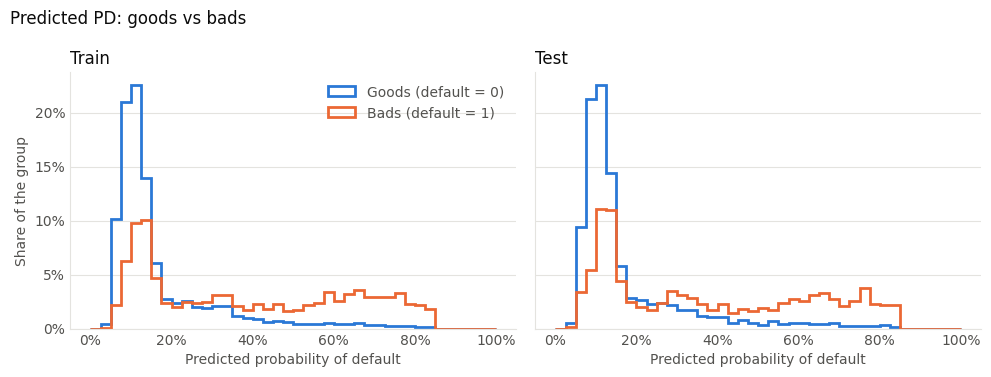

In [7]:
plot_pd_distribution({"Train": (train_pd, train_woe["default"]), "Test": (test_pd, test_woe["default"])})
plt.show()

How to read the histogram (each line is a share of its own group, so goods and bads are comparable):
- **Goods** pile up at low PDs: most are between about 5% and 17%, and very few are above 40%.
- **Bads fall into two groups.** About a third sit at the *same* low PDs as the goods (peak around 10–15%). The rest are spread
  almost evenly from about 20% up to 85%; these are mostly customers already behind on payments.
- **The low-PD bads are the model's limit.** They had a clean six-month history and defaulted without warning, which
  behavioural data can't foresee. No cut-off can separate them from the goods.
- Train and test look the same, a first sign the model isn't overfitting.

In [8]:
for name, data, pd_hat in [("train", train_woe, train_pd), ("test", test_woe, test_pd)]:
    save_processed(data[["id", "default"]].assign(pd=pd_hat), PROCESSED_DIR / f"{name}_pd.csv")

INFO scorecard.data: Saved 21000 rows to D:\Projects\Credit_analysis\data\processed\train_pd.csv


INFO scorecard.data: Saved 9000 rows to D:\Projects\Credit_analysis\data\processed\test_pd.csv
